# From impedance to wake potential: four scenarios

This walkthrough follows the conversions between impedance, wake function, and wake potential using IDDEFIX and Neffint.

| Scenario | Starting data | Main question |
| --- | --- | --- |
| Analytical resonator | A model impedance and its exact wake | How closely do Neffint's forward and inverse transforms recover the known pair? |
| SPS transitions | A simulated wake potential | Can deconvolution, inverse transformation, and reconvolution reproduce the potential? |
| SPS kickers | A tabulated transverse impedance | How sensitive is the inferred wake to frequency sampling and bandwidth? |
| IW2D resistive wall | A wake function sampled in time | How does the FFT bandwidth limit the wake recovered by an inverse transform? |

A **wake function** describes the structure's response to a point charge. A **wake potential** is that response convolved with the bunch distribution. compute_ineffint transforms impedance to wake, compute_neffint transforms wake to impedance, compute_convolution forms a wake potential, compute_deconvolution estimates impedance from a potential, and compute_fft transforms sampled wake data.

The analytical case has a direct reference. The SPS case tests a full data-processing chain. The kicker and IW2D cases show how frequency coverage and sampling affect numerical inversions; their limitations are described with each result.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c as c_light

import iddefix

plt.rcParams["figure.figsize"] = (10, 4)

## 1. Analytical resonator: check both transform directions

Start with a transverse resonator whose impedance and wake are known analytically. This gives a reference for both compute_ineffint (impedance to wake) and compute_neffint (wake to impedance). The finite frequency band and time window introduce numerical differences, especially close to the wake onset.

In [2]:
resonator_rs = 1e6  # Ohm/m
resonator_q = 20.0
resonator_fr = 1e9  # Hz
resonator_f = np.linspace(0, 8e9, 4001)
resonator_t = np.linspace(0, 30e-9, 3001)

# Analytical reference impedance for the transverse resonator.
resonator_z = iddefix.Impedances.Resonator_transverse_imp(
    resonator_f, resonator_rs, resonator_q, resonator_fr
)
# Analytical reference wake for the same resonator.
resonator_wake = iddefix.Wakes.Resonator_transverse_wake(
    resonator_t, resonator_rs, resonator_q, resonator_fr
)

# Transform impedance to wake and compare with the analytical wake.
_, resonator_wake_from_z = iddefix.compute_ineffint(
    resonator_f,
    resonator_z,
    times=resonator_t,
    plane="transverse",
    adaptative=False,
    interpolation="linear",
)
# Transform the analytical wake back to impedance.
_, resonator_z_from_wake = iddefix.compute_neffint(
    resonator_t,
    resonator_wake,
    frequencies=resonator_f,
    plane="transverse",
    adaptative=False,
    interpolation="linear",
)

wake_error = np.linalg.norm(resonator_wake_from_z - resonator_wake)
wake_error /= np.linalg.norm(resonator_wake)
impedance_error = np.linalg.norm(resonator_z_from_wake - resonator_z)
impedance_error /= np.linalg.norm(resonator_z)
print(f"Inverse-transform wake relative L2 difference: {wake_error:.2%}")
print(f"Forward-transform impedance relative L2 difference: {impedance_error:.2%}")

Inverse-transform wake relative L2 difference: 0.42%
Forward-transform impedance relative L2 difference: 0.90%


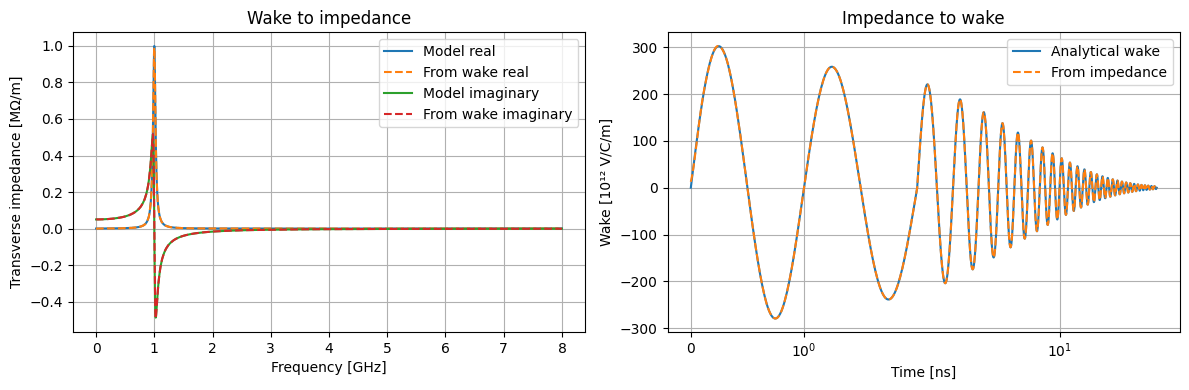

In [3]:
# Plot both transform checks against their analytical references.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(resonator_f / 1e9, resonator_z.real / 1e6, label="Model real")
axes[0].plot(
    resonator_f / 1e9, resonator_z_from_wake.real / 1e6, "--", label="From wake real"
)
axes[0].plot(resonator_f / 1e9, resonator_z.imag / 1e6, label="Model imaginary")
axes[0].plot(
    resonator_f / 1e9,
    resonator_z_from_wake.imag / 1e6,
    "--",
    label="From wake imaginary",
)
axes[0].set(
    xlabel="Frequency [GHz]",
    ylabel="Transverse impedance [MΩ/m]",
    title="Wake to impedance",
)
axes[1].plot(resonator_t * 1e9, resonator_wake / 1e12, label="Analytical wake")
axes[1].plot(
    resonator_t * 1e9, resonator_wake_from_z / 1e12, "--", label="From impedance"
)
axes[1].set(
    xlabel="Time [ns]",
    ylabel="Wake [10¹² V/C/m]",
    title="Impedance to wake",
    xscale="symlog",
)
for ax in axes:
    ax.grid()
    ax.legend()
fig.tight_layout()

## 2. SPS transitions: deconvolve, invert, and reconvolve

The SPS file contains a simulated transverse wake potential for a Gaussian bunch with $\sigma=100$ ps. Deconvolution estimates the impedance; the transverse convention is then applied before compute_ineffint recovers the wake function. Convolving that wake with the same bunch gives a potential to compare with the input.

This round trip checks the whole chain, including the finite frequency band and sampled data. It is not an independent accuracy test of Neffint alone.

In [11]:
# Load the SPS wake-potential data; its time column is in ns.
sps_data = np.loadtxt(
    "data/004_SPS_model_transitions_q26.txt",
    comments="#",
    delimiter="\t",
)
sps_time = sps_data[:, 0] * 1e-9  # file time is in ns
sps_potential = sps_data[:, 2]
sps_sigma = 0.5e-10

# Estimate impedance from the potential; rolloff tapers frequencies above ~1/(3 sigma).
sps_f, sps_z = iddefix.compute_deconvolution(
    sps_time,
    sps_potential,
    sigma=sps_sigma,
    samples=3001,
    rolloff=0.6,
)
sps_z *= 1j  # transverse impedance convention

sps_wake_time = np.linspace(sps_time[0], sps_time[-1], 3000)
# Invert the impedance to recover the transverse wake.
_, sps_wake = iddefix.compute_ineffint(
    sps_f,
    sps_z,
    times=sps_wake_time,
    plane="transverse",
    adaptative=False,
    interpolation="linear",
)

# This time, enforce causality.
_, sps_wake_causal = iddefix.compute_ineffint(
    sps_f,
    sps_z,
    times=sps_wake_time,
    plane="transverse",
    adaptative=False,
    enforce_causality=True,
    interpolation="linear",
)

# Convolve the recovered wake with the same Gaussian bunch to reconstruct the potential.
sps_potential_time, sps_potential_reconstructed = iddefix.compute_convolution(
    sps_wake_time,
    sps_wake_causal / c_light,
    sigma=sps_sigma,
    kernel="scipy",
)

# Interoplate to compare the errors
sps_reference = np.interp(
    sps_potential_time,
    sps_time,
    sps_potential,
    left=np.nan,
    right=np.nan,
)
sps_comparison = (
    np.isfinite(sps_reference)
    & (sps_potential_time >= -0.3e-9)
    & (sps_potential_time <= 16e-9)
)
sps_roundtrip_error = np.linalg.norm(
    sps_potential_reconstructed[sps_comparison] - sps_reference[sps_comparison]
)
sps_roundtrip_error /= np.linalg.norm(sps_reference[sps_comparison])
print(f"Deconvolution starts rolling off at {1 / (3 * sps_sigma) / 1e9:.2f} GHz")
print(f"Potential round-trip relative L2 difference: {sps_roundtrip_error:.2%}")

[!] Warning: Wake is nonzero for t < 0; pass enforce_causality=True to zero those samples.
Deconvolution starts rolling off at 6.67 GHz
Potential round-trip relative L2 difference: 3.49%


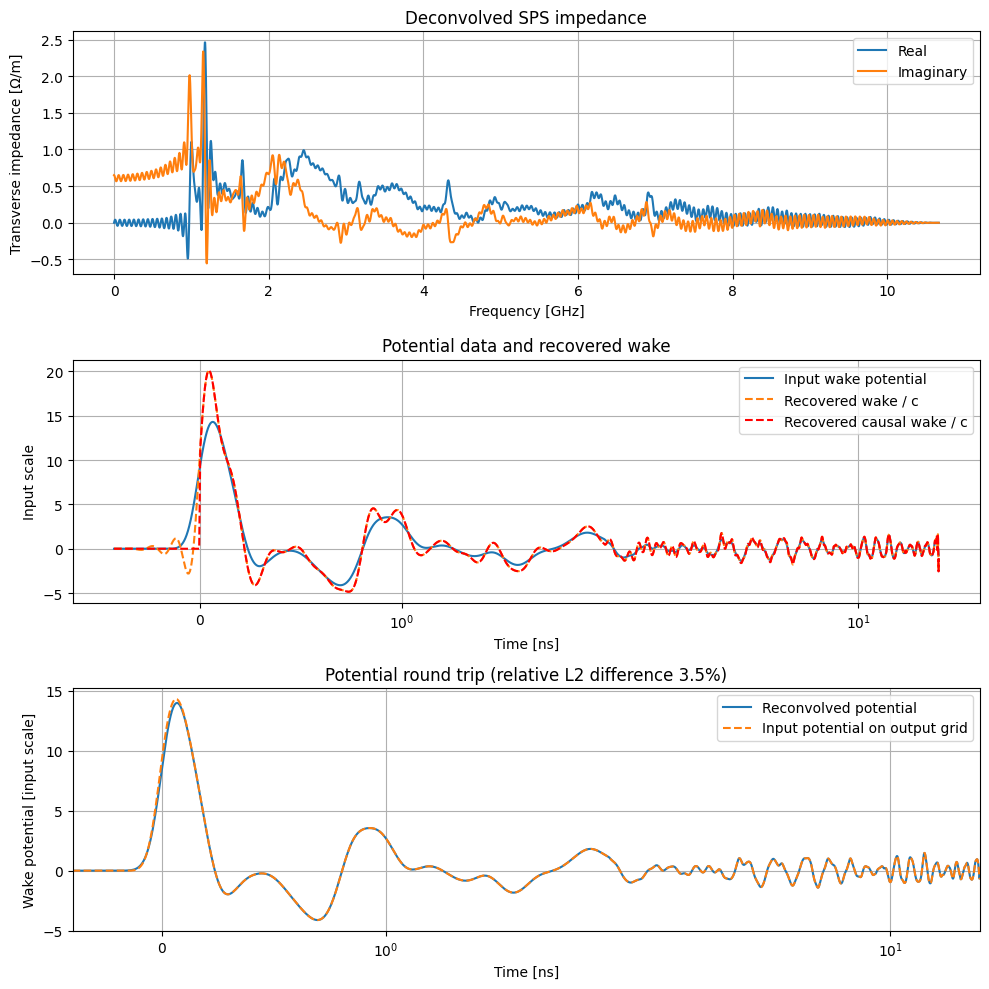

In [12]:
# Plot each stage of the SPS potential round trip.
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(sps_f / 1e9, sps_z.real, label="Real")
axes[0].plot(sps_f / 1e9, sps_z.imag, label="Imaginary")
axes[0].set(
    xlabel="Frequency [GHz]",
    ylabel="Transverse impedance [Ω/m]",
    title="Deconvolved SPS impedance",
)
axes[1].plot(sps_time * 1e9, sps_potential, label="Input wake potential")
axes[1].plot(sps_wake_time * 1e9, sps_wake / c_light, "--", label="Recovered wake / c")
axes[1].plot(
    sps_wake_time * 1e9,
    sps_wake_causal / c_light,
    "r--",
    label="Recovered causal wake / c",
)
axes[1].set(
    xlabel="Time [ns]",
    ylabel="Input scale",
    xscale="symlog",
    title="Potential data and recovered wake",
)
axes[2].plot(
    sps_potential_time * 1e9, sps_potential_reconstructed, label="Reconvolved potential"
)
axes[2].plot(
    sps_potential_time * 1e9,
    sps_reference,
    "--",
    label="Input potential on output grid",
)
axes[2].set(
    xlabel="Time [ns]",
    ylabel="Wake potential [input scale]",
    xscale="symlog",
    title=f"Potential round trip (relative L2 difference {sps_roundtrip_error:.1%})",
    xlim=(-0.4, 16.7),
)
for ax in axes:
    ax.grid()
    ax.legend()
fig.tight_layout()

## 3. SPS kickers: sampling and bandwidth change the inferred wake

The kicker file contains four complex transverse impedance components. Here we select **Driving Y** (the third data column). No exact time-domain wake is supplied, so the inverse from the full frequency grid serves as a numerical reference rather than ground truth.

Compare that reference with an inverse using every fifth frequency sample and one using only frequencies through 2 GHz. Thinning tests frequency-grid resolution; the cutoff tests how omitted high-frequency impedance changes the wake.

In [6]:
# Load the tabulated kicker impedance; frequencies in the file are in GHz.
kicker_data = np.loadtxt("data/008_Z_kickers_postLS2_SPSmodel.dat", dtype=str)
kicker_f = kicker_data[:, 0].astype(float) * 1e9
kicker_z = np.char.replace(kicker_data[:, 2], "i", "j").astype(complex)
kicker_time = np.linspace(0, 50e-9, 3000)

# Reference reconstruction using every frequency sample.
_, kicker_wake_full = iddefix.compute_ineffint(
    kicker_f,
    kicker_z,
    times=kicker_time,
    plane="transverse",
    adaptative=False,
    interpolation="linear",
)
# Thin the grid to test sensitivity to frequency sampling density.
_, kicker_wake_thin = iddefix.compute_ineffint(
    kicker_f[::5],
    kicker_z[::5],
    times=kicker_time,
    plane="transverse",
    adaptative=False,
    interpolation="linear",
)
# Limit the spectrum to 2 GHz to test sensitivity to bandwidth.
kicker_low_band = kicker_f <= 2e9
_, kicker_wake_low = iddefix.compute_ineffint(
    kicker_f[kicker_low_band],
    kicker_z[kicker_low_band],
    times=kicker_time,
    plane="transverse",
    adaptative=False,
    interpolation="linear",
)

kicker_thin_difference = np.linalg.norm(kicker_wake_thin - kicker_wake_full)
kicker_thin_difference /= np.linalg.norm(kicker_wake_full)
kicker_band_difference = np.linalg.norm(kicker_wake_low - kicker_wake_full)
kicker_band_difference /= np.linalg.norm(kicker_wake_full)
print(f"Every fifth frequency point: {kicker_thin_difference:.2%} relative difference")
print(f"2 GHz cutoff: {kicker_band_difference:.2%} relative difference")

Every fifth frequency point: 0.67% relative difference
2 GHz cutoff: 27.05% relative difference


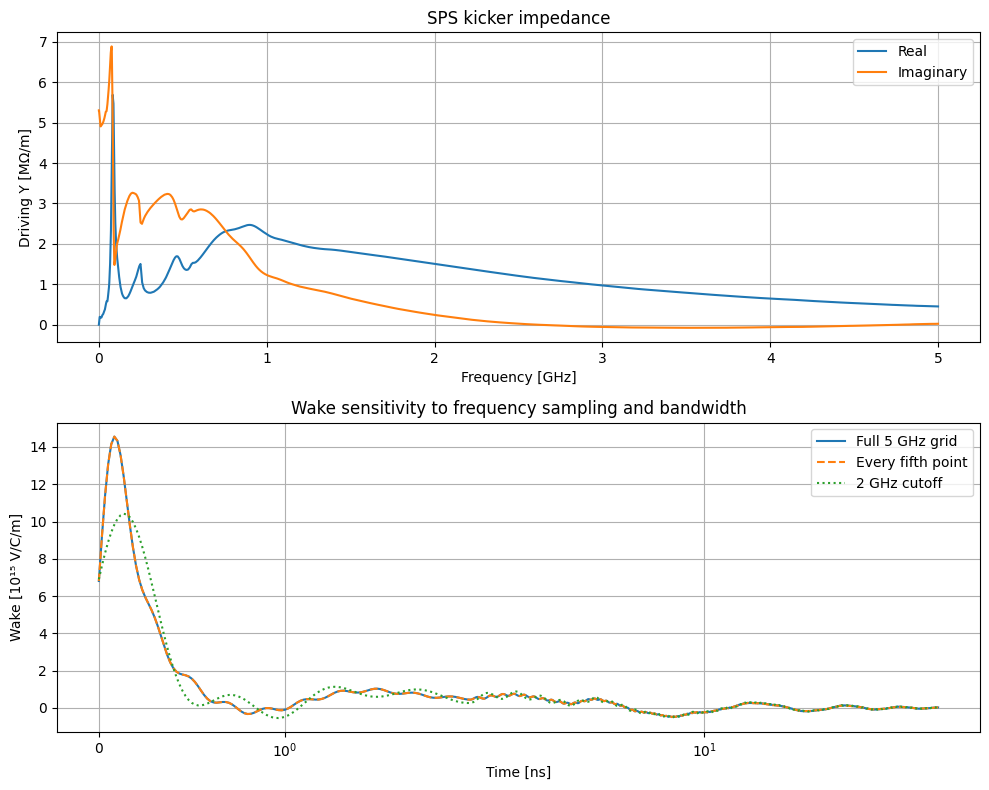

In [7]:
# Compare the wake reconstructions from the three frequency grids.
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(kicker_f / 1e9, kicker_z.real / 1e6, label="Real")
axes[0].plot(kicker_f / 1e9, kicker_z.imag / 1e6, label="Imaginary")
axes[0].set(
    xlabel="Frequency [GHz]", ylabel="Driving Y [MΩ/m]", title="SPS kicker impedance"
)
axes[1].plot(kicker_time * 1e9, kicker_wake_full / 1e15, label="Full 5 GHz grid")
axes[1].plot(
    kicker_time * 1e9, kicker_wake_thin / 1e15, "--", label="Every fifth point"
)
axes[1].plot(kicker_time * 1e9, kicker_wake_low / 1e15, ":", label="2 GHz cutoff")
axes[1].set(
    xlabel="Time [ns]",
    ylabel="Wake [10¹⁵ V/C/m]",
    xscale="symlog",
    title="Wake sensitivity to frequency sampling and bandwidth",
)
for ax in axes:
    ax.grid()
    ax.legend()
fig.tight_layout()

## 4. IW2D resistive wall: FFT bandwidth controls wake reconstruction

IW2D supplies a longitudinal wake function directly. We resample its rounded time coordinates onto an even grid, use compute_fft to obtain impedance, then apply compute_ineffint at three frequency limits.

IDDEFIX's FFT uses a distance increment $c\,\Delta t$, so the inverse output is divided by $c$ before comparing it with the input wake. The highest limit approaches the sampling grid's Nyquist frequency. Increasing the limit restores sharp time structure, while a lower limit smooths it and can produce ringing near abrupt features.

In [8]:
# Load the IW2D wake and resample it uniformly before using the FFT.
iw2d_data = np.loadtxt("data/006_beampipe_wake_iw2d.txt")
iw2d_raw_time = iw2d_data[:, 0]
iw2d_raw_wake = iw2d_data[:, 1] / 1e12  # V/pC
iw2d_time = np.linspace(iw2d_raw_time[0], iw2d_raw_time[-1], len(iw2d_raw_time))
# Interpolate because compute_fft expects regularly spaced time samples.
iw2d_wake = np.interp(iw2d_time, iw2d_raw_time, iw2d_raw_wake)

# Transform the sampled wake into impedance, retaining frequencies up to 10 THz.
iw2d_f, iw2d_z = iddefix.compute_fft(iw2d_time, iw2d_wake, fmax=10e12, samples=8192)
iw2d_eval_time = np.linspace(1e-13, iw2d_time[-1], 500)
# Put the original wake on the same time grid used for reconstruction.
iw2d_reference = np.interp(iw2d_eval_time, iw2d_time, iw2d_wake)
iw2d_cutoffs = (0.3e12, 2e12, 10e12)
iw2d_reconstructed = {}

for cutoff in iw2d_cutoffs:
    in_band = iw2d_f < cutoff
    # Invert only this cutoff band to show how bandwidth changes the wake.
    _, inverse_wake = iddefix.compute_ineffint(
        iw2d_f[in_band],
        iw2d_z[in_band],
        times=iw2d_eval_time,
        plane="longitudinal",
        adaptative=False,
        interpolation="linear",
    )
    iw2d_reconstructed[cutoff] = inverse_wake / c_light
    relative_difference = np.linalg.norm(
        iw2d_reconstructed[cutoff] - iw2d_reference
    ) / np.linalg.norm(iw2d_reference)
    print(
        f"{cutoff / 1e12:g} THz: {in_band.sum()} frequency points, "
        f"relative L2 difference {relative_difference:.2%}"
    )

0.3 THz: 123 frequency points, relative L2 difference 100.97%
2 THz: 820 frequency points, relative L2 difference 17.96%
10 THz: 4096 frequency points, relative L2 difference 6.79%


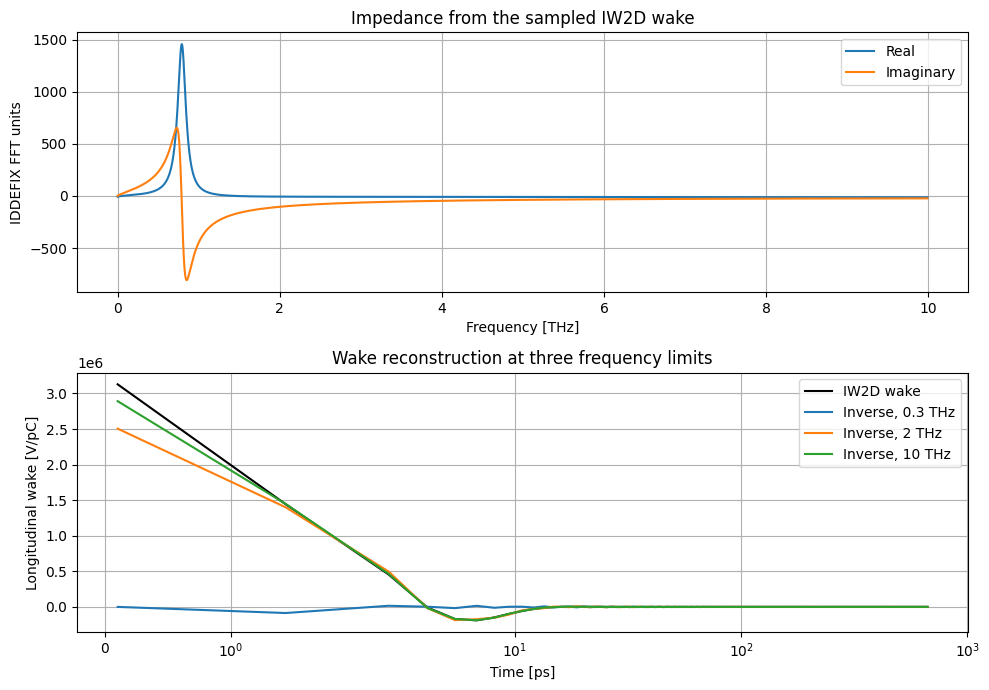

In [9]:
# Compare the input wake with inverse transforms at the selected cutoffs.
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].plot(iw2d_f / 1e12, iw2d_z.real, label="Real")
axes[0].plot(iw2d_f / 1e12, iw2d_z.imag, label="Imaginary")
axes[0].set(
    xlabel="Frequency [THz]",
    ylabel="IDDEFIX FFT units",
    title="Impedance from the sampled IW2D wake",
)
axes[1].plot(iw2d_eval_time * 1e12, iw2d_reference, color="black", label="IW2D wake")
for cutoff in iw2d_cutoffs:
    axes[1].plot(
        iw2d_eval_time * 1e12,
        iw2d_reconstructed[cutoff],
        label=f"Inverse, {cutoff / 1e12:g} THz",
    )
axes[1].set(
    xlabel="Time [ps]",
    ylabel="Longitudinal wake [V/pC]",
    xscale="symlog",
    title="Wake reconstruction at three frequency limits",
)
for ax in axes:
    ax.grid()
    ax.legend()
fig.tight_layout()